<a href="https://colab.research.google.com/github/FPetterini/econometria/blob/main/Tobit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratório 4 — Censura, variável latente e valores observados

**Econometria I · Capítulo 15**

**Referência:** Gujarati e Porter (2011), seção 15.11, pp. 570–573. Aplicação didática simulada com o mecanismo de censura explicitamente conhecido.


## Como trabalhar

Abra este arquivo `.ipynb` no [Google Colab](https://colab.research.google.com/), salve uma cópia e execute as células na ordem com ▶ ou **Shift + Enter**. Dê dois cliques nas células **Sua resposta** para escrever. Cada notebook funciona sozinho, com dados ou simulação incorporados; não exige montar o Drive.

O código dos exemplos está pronto. No exercício, substitua os campos `None` pelos valores solicitados. As células avisam quando falta preencher algo, sem interromper a execução. As respostas de referência estão recolhidas ao final.

In [ ]:
import importlib.util
import subprocess
import sys
if importlib.util.find_spec("statsmodels") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "statsmodels"])

from io import StringIO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.stats import norm, poisson
from scipy.special import expit
from IPython.display import display, HTML

%matplotlib inline
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.max_columns", 12)
print("Ambiente pronto. Execute as células na ordem.")

Ambiente pronto. Execute as células na ordem.


## 1. Uma variável quantitativa com censura · 0–10 min

Agora a variável dependente é um **valor em reais**. Imagine uma regra de bônus de produtividade: um cálculo interno gera um valor antes da aplicação de um piso; se esse cálculo for negativo, o pagamento será zero. Valores positivos são pagos integralmente.

Chamaremos o cálculo antes do piso de $Y_i^*$ e o pagamento observado de $Y_i$:

$$Y_i=\max(0,Y_i^*).$$

Se o cálculo interno for −R$ 200, o pagamento observado será R$ 0. Se for R$ 600, o pagamento observado será R$ 600. A base mantém o trabalhador com pagamento zero, mas o zero não revela quão negativo era o cálculo interno. Isso é **censura à esquerda em zero**.

| Variável | Significado e unidade |
|---|---|
| `bonus_reais` | Pagamento observado, em R$, incluindo zeros |
| `treinamento_horas` | Horas de treinamento no período |
| `anos_empresa` | Tempo de empresa, em anos |
| `bonus_latente` | Cálculo antes do piso; conhecido aqui porque simularemos os dados |

Os dados serão **simulados**, não um levantamento brasileiro real nem a base de casos extraconjugais do exemplo do livro. A simulação permite saber que o zero foi produzido por censura. Ter muitos zeros em uma base real, isoladamente, não demonstra que o Tobit seja o modelo adequado.

### Censura e truncamento

Na censura deste exemplo, conservamos a linha e observamos pagamento zero. Se removêssemos os trabalhadores com pagamento zero, teríamos uma amostra selecionada por esse resultado. Estimar apenas nos pagamentos positivos não recupera automaticamente a relação latente de toda a população.

In [ ]:
rng = np.random.default_rng(202604)
n = 600
dados = pd.DataFrame({
    "treinamento_horas": rng.uniform(0, 40, n),
    "anos_empresa": rng.uniform(0, 10, n),
})
regressores = ["treinamento_horas", "anos_empresa"]
X = sm.add_constant(dados[regressores], has_constant="add")
beta_verdadeiro = np.array([-900.0, 35.0, 90.0])
sigma_verdadeiro = 350.0
dados["bonus_latente"] = X.to_numpy() @ beta_verdadeiro + rng.normal(0, sigma_verdadeiro, n)
dados["bonus_reais"] = np.maximum(0, dados["bonus_latente"])
print(f"Observações: {n} | Pagamentos zero: {(dados.bonus_reais == 0).mean():.1%}")
display(dados.head(6).round(2))

Observações: 600 | Pagamentos zero: 32.5%


,treinamento_horas,anos_empresa,bonus_latente,bonus_reais
0,22.46,4.92,826.88,826.88
1,16.99,6.59,-498.86,0.00
2,0.80,9.77,269.15,269.15
3,28.09,0.46,106.25,106.25
4,20.96,9.38,210.86,210.86
5,28.51,8.51,972.47,972.47


## 2. O que o Tobit modela? · 10–20 min

A equação latente desta aplicação é:

$$Y_i^*=\beta_1+\beta_2\,treinamento_i+\beta_3\,anos_i+u_i,$$

com $u_i\mid X_i\sim N(0,\sigma^2)$ e $Y_i=\max(0,Y_i^*)$. Neste modelo básico, a dispersão latente $\sigma$ é constante. Na simulação, o erro é sorteado independentemente dos regressores, com a distribuição especificada.

**Observe a diferença em relação ao probit:** no probit, observávamos apenas 0 ou 1; aqui observamos o valor monetário quando ele está acima do piso. O Tobit usa tanto a informação de estar no zero quanto os montantes positivos.

Uma hora adicional de treinamento muda o **valor latente esperado** em $\beta_2$ reais. O efeito sobre o **pagamento médio observado**, incluindo zeros, depende também da probabilidade de ficar acima do piso.

### Por que máxima verossimilhança?

Para uma observação zero, a contribuição é a probabilidade de $Y_i^*\leq0$. Para uma observação positiva, usamos a densidade normal no valor registrado. O programa combina essas duas partes na estimação.

Sob a especificação correta, identificação e condições usuais, a máxima verossimilhança é consistente. A hipótese de exogeneidade é importante, mas o Tobit normal básico também depende da distribuição e da homocedasticidade do erro latente. Uma correção da matriz de covariância não garante consistência se esses pressupostos que afetam a média observada estiverem errados.

## 3. Estimação e comparação com MQO · 20–32 min

A rotina abaixo contém a verossimilhança do Tobit. Ela está pronta para uso; não é necessário programá-la durante a aula. A otimização trabalha com o logaritmo de sigma, garantindo uma dispersão positiva.

In [ ]:
#@title Rotina de estimação Tobit — execute sem modificar
import numpy as np
from scipy.stats import norm
from statsmodels.base.model import GenericLikelihoodModel


class TobitZero(GenericLikelihoodModel):
    """Tobit normal homocedástico, censurado à esquerda em zero."""
    def __init__(self, endog, exog):
        super().__init__(endog, exog, extra_params_names=["ln_sigma"])

    def loglikeobs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        mu = self.exog @ beta
        z = (self.endog - mu) / sigma
        return np.where(self.endog > 0,
                        norm.logpdf(z) - log_sigma,
                        norm.logcdf(-mu / sigma))

    def score_obs(self, params):
        beta, log_sigma = params[:-1], params[-1]
        sigma = np.exp(log_sigma)
        mu = self.exog @ beta
        z = (self.endog - mu) / sigma
        a = -mu / sigma
        mills = np.exp(norm.logpdf(a) - norm.logcdf(a))
        positive = self.endog > 0
        score_mu = np.where(positive, z / sigma, -mills / sigma)
        score_scale = np.where(positive, z*z - 1, -a * mills)
        return np.column_stack((self.exog * score_mu[:, None], score_scale))

    def score(self, params):
        return self.score_obs(params).sum(axis=0)

    def fit(self, start_params=None, **kwargs):
        if start_params is None:
            beta0 = np.linalg.lstsq(self.exog, self.endog, rcond=None)[0]
            residual = self.endog - self.exog @ beta0
            sigma0 = max(float(np.std(residual)), 0.1)
            start_params = np.r_[beta0, np.log(sigma0)]
        return super().fit(start_params=start_params, method="bfgs", maxiter=1000,
                           disp=False, **kwargs)

In [ ]:
# Dividir o pagamento por 100 melhora a escala numérica da otimização.
# As tabelas abaixo convertem os coeficientes e os erros padrão de volta para reais.
escala_monetaria = 100.0
tobit = TobitZero(dados["bonus_reais"] / escala_monetaria, X).fit()
nomes = list(X.columns)
coef_tobit = pd.Series(tobit.params[:-1] * escala_monetaria, index=nomes)
ep_tobit = pd.Series(tobit.bse[:-1] * escala_monetaria, index=nomes)
sigma_tobit = float(np.exp(tobit.params[-1]) * escala_monetaria)

z_tobit = coef_tobit / ep_tobit
tabela_tobit = pd.DataFrame({
    "Coeficiente latente (R$)": coef_tobit,
    "EP usual (R$)": ep_tobit,
    "z": z_tobit,
    "p-valor normal": 2 * norm.sf(np.abs(z_tobit)),
})
display(tabela_tobit.style.format("{:.4f}"))
print(f"Sigma latente estimado: R$ {sigma_tobit:.2f}")
print(f"Convergência: {tobit.mle_retvals['converged']}")

mqotodos = sm.OLS(dados["bonus_reais"], X).fit()
positivos = dados["bonus_reais"] > 0
mqopositivos = sm.OLS(dados.loc[positivos, "bonus_reais"], X.loc[positivos]).fit()
comparacao_coef = pd.DataFrame({
    "Parâmetro latente usado na simulação": beta_verdadeiro,
    "MQO: todos os pagamentos": mqotodos.params,
    "MQO: só pagamentos positivos": mqopositivos.params,
    "Tobit: equação latente": coef_tobit,
}, index=nomes)
display(comparacao_coef.style.format("{:.2f}"))

Sigma latente estimado: R$ 354.71
Convergência: True


,Coeficiente latente (R$),EP usual (R$),z,p-valor normal
const,-943.2422,54.6535,-17.2586,0.0000
treinamento_horas,35.6815,1.5159,23.5389,0.0000
anos_empresa,93.5474,5.8247,16.0606,0.0000


,Parâmetro latente usado na simulação,MQO: todos os pagamentos,MQO: só pagamentos positivos,Tobit: equação latente
const,-900.00,-444.39,-400.52,-943.24
treinamento_horas,35.00,24.92,24.59,35.68
anos_empresa,90.00,65.01,66.90,93.55


Na simulação, o parâmetro latente de treinamento é R$ 35 por hora. O MQO sobre os pagamentos observados ajusta uma relação linear para uma média que foi alterada pelo piso; o MQO só nos positivos usa uma amostra selecionada. Seus coeficientes não têm automaticamente o mesmo significado do coeficiente latente do Tobit.

O parâmetro verdadeiro é conhecido porque criamos a base. Uma única amostra permite verificar diferenças numéricas, mas a definição de viés envolve repetir a amostragem. Não esperamos que a estimativa Tobit coincida exatamente com o valor usado na geração.

Os erros padrão usuais vêm da curvatura da log-verossimilhança. A razão estimativa/EP recebe referência normal assintótica, e não uma distribuição t exata de pequena amostra.

## 4. Duas previsões diferentes · 32–42 min

Defina $\mu_i=X_i'\beta$. O Tobit permite calcular, entre outras coisas:

| Pergunta | Quantidade |
|---|---|
| Qual a probabilidade de receber um bônus positivo? | $P(Y_i>0\mid X_i)=\Phi(\mu_i/\sigma)$ |
| Qual o pagamento médio, incluindo quem recebe zero? | $E(Y_i\mid X_i)=\mu_i\Phi(\mu_i/\sigma)+\sigma\phi(\mu_i/\sigma)$ |

O valor latente esperado, $\mu_i$, pode ser negativo. O pagamento médio observado é não negativo. Por isso, precisamos dizer **qual dessas quantidades** estamos interpretando.

O efeito local de uma hora a mais de treinamento sobre o pagamento médio observado é $\Phi(\mu_i/\sigma)\beta_{treinamento}$. Ele difere do coeficiente latente e varia entre perfis.

In [ ]:
def prever_tobit(perfis):
    Xp = sm.add_constant(perfis[regressores], has_constant="add")
    mu = Xp.to_numpy() @ coef_tobit.to_numpy()
    z = mu / sigma_tobit
    return perfis.assign(
        media_latente=mu,
        prob_bonus_positivo=norm.cdf(z),
        pagamento_medio=mu*norm.cdf(z) + sigma_tobit*norm.pdf(z),
        efeito_local_treinamento=norm.cdf(z)*coef_tobit["treinamento_horas"],
    )

perfis = pd.DataFrame({"treinamento_horas": [10, 30], "anos_empresa": [3, 3]},
                      index=["A", "B"])
previsoes = prever_tobit(perfis)
display(previsoes.style.format({
    "media_latente": "R$ {:.2f}", "prob_bonus_positivo": "{:.2%}",
    "pagamento_medio": "R$ {:.2f}", "efeito_local_treinamento": "R$ {:.2f}",
}))

,treinamento_horas,anos_empresa,media_latente,prob_bonus_positivo,pagamento_medio,efeito_local_treinamento
A,10,3,R$ -305.78,19.43%,R$ 38.17,R$ 6.93
B,30,3,R$ 407.85,87.49%,R$ 429.88,R$ 31.22


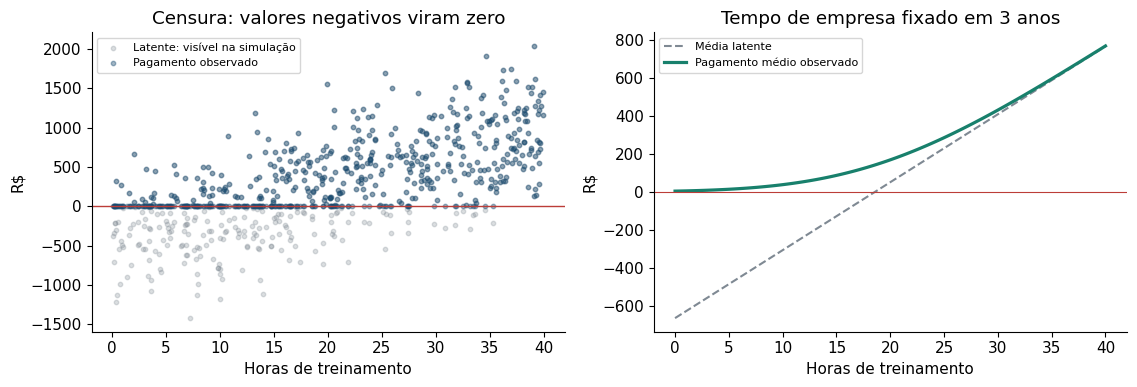

In [ ]:
fig, eixos = plt.subplots(1, 2, figsize=(11.5, 4))
eixos[0].scatter(dados["treinamento_horas"], dados["bonus_latente"],
                 s=10, alpha=0.28, color="#7f8993", label="Latente: visível na simulação")
eixos[0].scatter(dados["treinamento_horas"], dados["bonus_reais"],
                 s=10, alpha=0.4, color="#174a70", label="Pagamento observado")
eixos[0].axhline(0, color="#bc3d38", linewidth=1)
eixos[0].set(xlabel="Horas de treinamento", ylabel="R$", title="Censura: valores negativos viram zero")
eixos[0].legend(fontsize=8)

grade = pd.DataFrame({"treinamento_horas": np.linspace(0, 40, 120), "anos_empresa": 3})
pg = prever_tobit(grade)
eixos[1].plot(grade.treinamento_horas, pg.media_latente, color="#7f8993", linestyle="--", label="Média latente")
eixos[1].plot(grade.treinamento_horas, pg.pagamento_medio, color="#18806c", linewidth=2.3, label="Pagamento médio observado")
eixos[1].axhline(0, color="#bc3d38", linewidth=0.8)
eixos[1].set(xlabel="Horas de treinamento", ylabel="R$", title="Tempo de empresa fixado em 3 anos")
eixos[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. Incerteza e bootstrap · 42–50 min

Vamos comparar os erros padrão usuais da verossimilhança com o **bootstrap de pares**. Sortearemos trabalhadores, mantendo suas variáveis juntas, e reestimaremos o mesmo Tobit. O desvio-padrão dos coeficientes nas reamostras fornecerá outro erro padrão.

Esta demonstração usa 499 reamostras para manter a execução curta. O ponto estimado reportado permanece sendo o da amostra original. O bootstrap não elimina endogeneidade nem corrige uma especificação Tobit inadequada, como supor homocedasticidade latente quando ela falha de forma relevante para a média observada.

In [ ]:
#@title Bootstrap do Tobit — a rotina está pronta
B = 499
rng_boot = np.random.default_rng(20260499)
coef_boot = []
y_array = dados.bonus_reais.to_numpy() / escala_monetaria
X_array = X.to_numpy()
for _ in range(B):
    indices = rng_boot.integers(0, len(dados), size=len(dados))
    resultado_b = TobitZero(y_array[indices], X_array[indices]).fit(start_params=tobit.params)
    if resultado_b.mle_retvals["converged"] and np.isfinite(resultado_b.params).all():
        coef_boot.append(resultado_b.params[:-1] * escala_monetaria)

coef_boot = np.asarray(coef_boot)
if len(coef_boot) < 0.9 * B:
    raise RuntimeError("Convergiram poucas reamostras; reveja a otimização antes de interpretar o bootstrap.")
V_boot = np.cov(coef_boot, rowvar=False, ddof=1)
ep_boot = pd.Series(np.sqrt(np.diag(V_boot)), index=nomes)
comparacao_ep = pd.DataFrame({
    "Coeficiente original (R$)": coef_tobit,
    "EP usual (R$)": ep_tobit,
    "EP bootstrap (R$)": ep_boot,
})
display(comparacao_ep.style.format("{:.3f}"))
print(f"Reamostras convergentes: {len(coef_boot)} de {B}.")

Reamostras convergentes: 499 de 499.


,Coeficiente original (R$),EP usual (R$),EP bootstrap (R$)
const,-943.242,54.654,53.971
treinamento_horas,35.682,1.516,1.557
anos_empresa,93.547,5.825,5.702


Cada erro padrão é a raiz de uma variância na diagonal da respectiva matriz de covariância. A comparação é entre duas medidas de incerteza para os mesmos coeficientes latentes, na mesma unidade monetária.

Aqui não calculamos um teste bootstrap-t: dividir a estimativa pelo EP bootstrap, isoladamente, não cria uma distribuição t exata. O desempenho inferencial em amostras pequenas também não é garantido pela simples reamostragem.

## 6. Exercício prático · 50–58 min

**Nome:** escreva aqui.

### A. Identificando a censura · 2 min

Preencha um valor latente de −200 reais. Quanto seria observado? O zero observado permite recuperar esse valor latente exato?

In [ ]:
valor_latente_exercicio = None
if valor_latente_exercicio is None:
    print("Preencha o valor latente solicitado.")
else:
    print(f"Valor observado: R$ {max(0, valor_latente_exercicio):.2f}")

Preencha o valor latente solicitado.


**Sua resposta — A:** Explique por que diversos valores latentes podem produzir o mesmo zero observado.

> Escreva aqui.

### B. Prevendo para dois perfis · 3 min

Preencha treinamento de 10 e 30 horas, ambos com 3 anos de empresa. Compare a probabilidade de bônus positivo e o pagamento médio observado. A diferença média equivale a 20 vezes o coeficiente latente?

In [ ]:
horas_iniciais = None
horas_finais = None
if horas_iniciais is None or horas_finais is None:
    print("Preencha 10 e 30 horas.")
else:
    pe = pd.DataFrame({"treinamento_horas": [horas_iniciais, horas_finais], "anos_empresa": [3, 3]})
    previsoes_exercicio = prever_tobit(pe)
    display(previsoes_exercicio.round(4))
    diferenca_observada = previsoes_exercicio.pagamento_medio.iloc[1] - previsoes_exercicio.pagamento_medio.iloc[0]
    diferenca_latente = (horas_finais-horas_iniciais)*coef_tobit["treinamento_horas"]
    print(f"Diferença no pagamento médio: R$ {diferenca_observada:.2f}")
    print(f"Diferença na média latente: R$ {diferenca_latente:.2f}")

Preencha 10 e 30 horas.


**Sua resposta — B:** Distinga probabilidade, média latente e média observada na sua interpretação.

> Escreva aqui.

### C. Pressupostos e incerteza · 3 min

Compare os dois erros padrão do coeficiente de treinamento. Eles estão em reais ou em pontos percentuais? Uma matriz robusta ou um bootstrap garantiriam consistência se a regra de censura ou a distribuição do erro latente estivesse mal especificada?

**Sua resposta — C:** Relacione a unidade dos coeficientes aos pressupostos de estimação e aos procedimentos de inferência.

> Escreva aqui.

## 7. Fechamento · 58–60 min

O Tobit articula uma variável latente contínua e uma regra de censura conhecida. O coeficiente latente, a probabilidade de ficar acima do piso e a média observada são quantidades distintas. Na próxima aula, estudaremos contagens, em que zeros podem ser realizações naturais do processo.

## Conferência após resolver

<details>
<summary><strong>Abrir respostas de referência</strong></summary>

**A.** O valor observado é **R$ 0**. Um cálculo latente de −200, −500 ou outro valor negativo gera o mesmo pagamento zero. Não recuperamos o latente individual apenas com esse zero.

**B.** No perfil A, a probabilidade de bônus positivo é aproximadamente **19,43%**, a média latente é **−R$ 305,78** e o pagamento médio observado é **R$ 38,17**. No perfil B, são aproximadamente **87,49%**, **R$ 407,85** e **R$ 429,88**. A diferença no pagamento médio é **R$ 391,71**, enquanto a diferença na média latente é **R$ 713,63**. A média observada incorpora o piso e não é obtida aplicando diretamente o coeficiente latente a uma mudança de 20 horas.

**C.** Os coeficientes e seus erros padrão estão em **reais**, por unidade do regressor: para treinamento, por hora. A estimativa latente de treinamento é aproximadamente **R$ 35,68 por hora**, com EP usual de aproximadamente **R$ 1,52** e EP bootstrap de aproximadamente **R$ 1,56**, com a semente e as 499 reamostras fornecidas. O efeito na média observada é menor e varia entre perfis. Reamostragem e correções da matriz não garantem consistência sob uma regra de censura ou distribuição latente inadequada.

Na geração, 32,5% dos trabalhadores têm pagamento zero. A estimação Tobit usa todas essas observações.

</details>

## Referências e relação com o livro

- **Gujarati, D. N.; Porter, D. C.** *Econometria básica*. 5. ed. Porto Alegre: AMGH, 2011. Capítulo 15, seção 15.11, pp. 570–573. A regra de censura e a interpretação da variável latente seguem o modelo da seção. A aplicação de bônus é uma simulação didática própria, com erro normal homocedástico e regressores exógenos por construção.
- As explicações e os exercícios foram redigidos para a aula. As extensões de inferência são demonstrações computacionais; não são tabelas adicionais atribuídas ao livro.
- Documentação técnica: [verossimilhança genérica](https://www.statsmodels.org/stable/dev/generated/statsmodels.base.model.GenericLikelihoodModel.html) e [normal acumulada/densidade](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.norm.html).